In [1]:
%pip install pandas scikit-learn matplotlib seaborn joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
train_path = "train_data.txt"
test_path = "test_data.txt"
solution_path = "test_data_solution.txt"

print("Dataset file paths set successfully!")

Dataset file paths set successfully!


In [4]:
train_df = pd.read_csv(
    train_path,
    sep=r"\s*:::\s*",
    engine="python",
    header=None,
    names=["id", "title", "genre", "description"],
    dtype={"id": str}
)

print("Training dataset loaded!")
print("Shape:", train_df.shape)

display(train_df.head())

Training dataset loaded!
Shape: (54214, 4)


,id,title,genre,description
0,1,Oscar et la dame rose (2009),drama,Listening in to a conversation between his doc...
1,2,Cupid (1997),thriller,A brother and sister with a past incestuous re...
2,3,"Young, Wild and Wonderful (1980)",adult,As the bus empties the students for their fiel...
3,4,The Secret Sin (1915),drama,To help their unemployed father make ends meet...
4,5,The Unrecovered (2007),drama,The film's title refers not only to the un-rec...


In [5]:
test_df = pd.read_csv(
    test_path,
    sep=r"\s*:::\s*",
    engine="python",
    header=None,
    names=["id", "title", "description"],
    dtype={"id": str}
)

print("Test dataset loaded!")
print("Shape:", test_df.shape)

display(test_df.head())

Test dataset loaded!
Shape: (54200, 3)


,id,title,description
0,1,Edgar's Lunch (1998),"L.R. Brane loves his life - his car, his apart..."
1,2,La guerra de papá (1977),"Spain, March 1964: Quico is a very naughty chi..."
2,3,Off the Beaten Track (2010),One year in the life of Albin and his family o...
3,4,Meu Amigo Hindu (2015),"His father has died, he hasn't spoken with his..."
4,5,Er nu zhai (1955),Before he was known internationally as a marti...


In [6]:
solution_df = pd.read_csv(
    solution_path,
    sep=r"\s*:::\s*",
    engine="python",
    header=None,
    names=["id", "title", "genre", "description"],
    dtype={"id": str}
)

print("Test solution loaded!")
print("Shape:", solution_df.shape)

display(solution_df.head())

Test solution loaded!
Shape: (54200, 4)


,id,title,genre,description
0,1,Edgar's Lunch (1998),thriller,"L.R. Brane loves his life - his car, his apart..."
1,2,La guerra de papá (1977),comedy,"Spain, March 1964: Quico is a very naughty chi..."
2,3,Off the Beaten Track (2010),documentary,One year in the life of Albin and his family o...
3,4,Meu Amigo Hindu (2015),drama,"His father has died, he hasn't spoken with his..."
4,5,Er nu zhai (1955),drama,Before he was known internationally as a marti...


In [7]:
print("Training data information:")
train_df.info()

print("\nMissing values in training data:")
print(train_df.isnull().sum())

print("\nTotal training movies:", len(train_df))
print("Total genres:", train_df["genre"].nunique())

print("\nAvailable genres:")
print(sorted(train_df["genre"].dropna().unique()))

Training data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54214 entries, 0 to 54213
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           54214 non-null  object
 1   title        54214 non-null  object
 2   genre        54214 non-null  object
 3   description  54214 non-null  object
dtypes: object(4)
memory usage: 1.7+ MB

Missing values in training data:
id             0
title          0
genre          0
description    0
dtype: int64

Total training movies: 54214
Total genres: 27

Available genres:
['action', 'adult', 'adventure', 'animation', 'biography', 'comedy', 'crime', 'documentary', 'drama', 'family', 'fantasy', 'game-show', 'history', 'horror', 'music', 'musical', 'mystery', 'news', 'reality-tv', 'romance', 'sci-fi', 'short', 'sport', 'talk-show', 'thriller', 'war', 'western']


In [8]:
train_df = train_df.dropna(
    subset=["title", "genre", "description"]
).copy()

test_df = test_df.dropna(
    subset=["title", "description"]
).copy()

solution_df = solution_df.dropna(
    subset=["id", "genre"]
).copy()

train_df["title"] = train_df["title"].astype(str).str.strip()
train_df["genre"] = train_df["genre"].astype(str).str.strip()
train_df["description"] = train_df["description"].astype(str).str.strip()

test_df["title"] = test_df["title"].astype(str).str.strip()
test_df["description"] = test_df["description"].astype(str).str.strip()

solution_df["genre"] = solution_df["genre"].astype(str).str.strip()

train_df = train_df[
    (train_df["genre"] != "") &
    (train_df["description"] != "")
].copy()

train_df = train_df.drop_duplicates(
    subset=["title", "description"]
)

print("Cleaning completed!")
print("Training rows after cleaning:", len(train_df))
print("Test rows after cleaning:", len(test_df))

Cleaning completed!
Training rows after cleaning: 54214
Test rows after cleaning: 54200


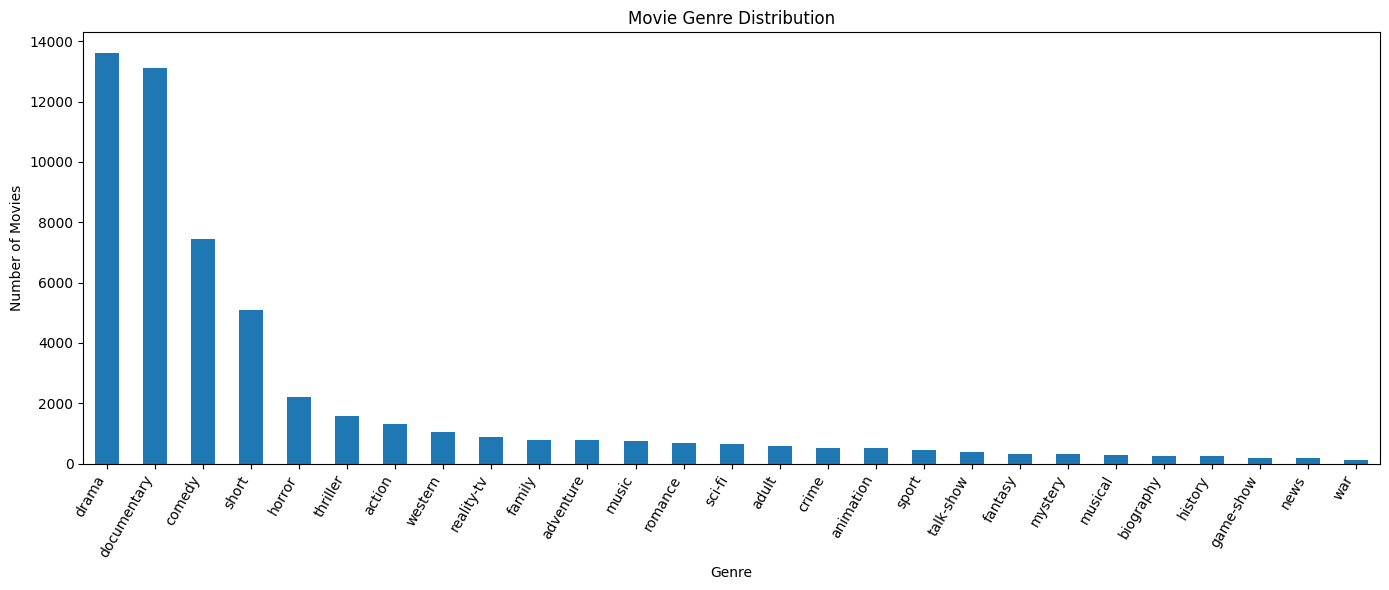

In [9]:
plt.figure(figsize=(14, 6))

train_df["genre"].value_counts().plot(kind="bar")

plt.title("Movie Genre Distribution")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()

plt.show()

In [10]:
X = (
    train_df["title"] + " " + train_df["description"]
)

y = train_df["genre"]

print("Input text prepared!")
print("Total training samples:", len(X))
print("Total target labels:", len(y))

Input text prepared!
Total training samples: 54214
Total target labels: 54214


In [11]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

Training samples: 43371
Validation samples: 10843


In [12]:
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            stop_words="english",
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2
        )
    ),
    (
        "classifier",
        LinearSVC(class_weight="balanced", random_state=42)
    )
])

print("Model pipeline created!")

Model pipeline created!


In [13]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [14]:
y_val_pred = model.predict(X_val)

print("Validation predictions completed!")
print("First 10 predictions:")
print(y_val_pred[:10])

Validation predictions completed!
First 10 predictions:
['short' 'sci-fi' 'adult' 'drama' 'horror' 'short' 'documentary' 'horror'
 'romance' 'horror']


In [15]:
accuracy = accuracy_score(y_val, y_val_pred)

print(f"Validation Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")

print(
    classification_report(
        y_val,
        y_val_pred,
        zero_division=0
    )
)

Validation Accuracy: 56.19%

Classification Report:
              precision    recall  f1-score   support

      action       0.35      0.49      0.41       263
       adult       0.46      0.66      0.54       118
   adventure       0.27      0.30      0.28       155
   animation       0.19      0.22      0.21       100
   biography       0.00      0.00      0.00        53
      comedy       0.58      0.56      0.57      1490
       crime       0.12      0.12      0.12       101
 documentary       0.75      0.76      0.75      2619
       drama       0.66      0.55      0.60      2723
      family       0.23      0.27      0.25       157
     fantasy       0.13      0.14      0.14        65
   game-show       0.71      0.56      0.63        39
     history       0.17      0.12      0.14        49
      horror       0.59      0.72      0.65       441
       music       0.49      0.68      0.57       146
     musical       0.15      0.15      0.15        55
     mystery       0.07      

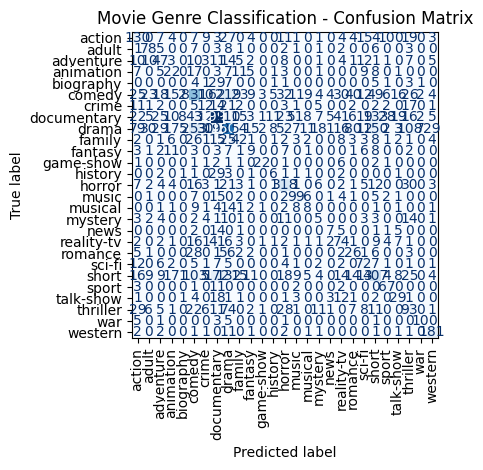

In [16]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    xticks_rotation="vertical",
    cmap="Blues",
    colorbar=False
)

plt.title("Movie Genre Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
X_full = (
    train_df["title"] + " " + train_df["description"]
)

y_full = train_df["genre"]

model.fit(X_full, y_full)

print("Final model trained on full training dataset!")

In [ ]:
X_test = (
    test_df["title"] + " " + test_df["description"]
)

test_predictions = model.predict(X_test)

predictions_df = test_df[["id", "title"]].copy()
predictions_df["predicted_genre"] = test_predictions

display(predictions_df.head(10))

,id,title,predicted_genre
0,1,Edgar's Lunch (1998),short
1,2,La guerra de papá (1977),drama
2,3,Off the Beaten Track (2010),documentary
3,4,Meu Amigo Hindu (2015),drama
4,5,Er nu zhai (1955),biography
5,6,Riddle Room (2016),adult
6,7,L'amica (1969),drama
7,8,Ina Mina Dika (1989),comedy
8,9,Equinox Special: Britain's Tornados (2005),documentary
9,10,Press (2011),drama


In [ ]:
actual_labels = solution_df[["id", "genre"]].copy()

comparison_df = predictions_df.merge(
    actual_labels,
    on="id",
    how="inner",
    validate="one_to_one"
)

comparison_df = comparison_df.rename(
    columns={"genre": "actual_genre"}
)

print("Matched test records:", len(comparison_df))

display(comparison_df.head(10))

Matched test records: 54200


,id,title,predicted_genre,actual_genre
0,1,Edgar's Lunch (1998),short,thriller
1,2,La guerra de papá (1977),drama,comedy
2,3,Off the Beaten Track (2010),documentary,documentary
3,4,Meu Amigo Hindu (2015),drama,drama
4,5,Er nu zhai (1955),biography,drama
5,6,Riddle Room (2016),adult,horror
6,7,L'amica (1969),drama,drama
7,8,Ina Mina Dika (1989),comedy,comedy
8,9,Equinox Special: Britain's Tornados (2005),documentary,documentary
9,10,Press (2011),drama,drama


In [ ]:
test_accuracy = accuracy_score(
    comparison_df["actual_genre"],
    comparison_df["predicted_genre"]
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

print("\nTest Classification Report:")

print(
    classification_report(
        comparison_df["actual_genre"],
        comparison_df["predicted_genre"],
        zero_division=0
    )
)

Test Accuracy: 57.01%

Test Classification Report:
              precision    recall  f1-score   support

      action       0.35      0.48      0.40      1314
       adult       0.48      0.64      0.55       590
   adventure       0.30      0.33      0.31       775
   animation       0.25      0.26      0.25       498
   biography       0.06      0.05      0.05       264
      comedy       0.60      0.56      0.58      7446
       crime       0.17      0.21      0.19       505
 documentary       0.76      0.77      0.76     13096
       drama       0.67      0.56      0.61     13612
      family       0.21      0.26      0.23       783
     fantasy       0.16      0.17      0.17       322
   game-show       0.66      0.72      0.68       193
     history       0.11      0.07      0.09       243
      horror       0.55      0.71      0.62      2204
       music       0.50      0.69      0.58       731
     musical       0.18      0.18      0.18       276
     mystery       0.17      0

In [ ]:
predictions_df.to_csv(
    "movie_genre_predictions.csv",
    index=False
)

print("Predictions saved successfully!")

Predictions saved successfully!


In [ ]:
joblib.dump(model, "movie_genre_model.pkl")

print("Trained model saved successfully!")

Trained model saved successfully!


In [ ]:
movie_title = input("Enter movie title: ")
movie_description = input("Enter movie description: ")

movie_text = movie_title + " " + movie_description

prediction = model.predict([movie_text])[0]

print("\nMovie Title:", movie_title)
print("Predicted Genre:", prediction)

In [ ]:
import os

print("Project files:")

for file in os.listdir("."):
    if file.endswith((".ipynb", ".pkl", ".csv", ".txt")):
        print(file)